# Auditoría de viabilidad histórica — Oslo, Dietz (2018)

**Primera fase: datos y dictamen antes de modificar el motor.** Se conservan los experimentos de cinco colmenas y los notebooks anteriores. Este documento no ejecuta simulaciones históricas ni optimización. La comparación histórica todavía no está habilitada: faltan CRS/datum y ubicaciones de colmenas verificadas.

Fuente primaria: [tesis publicada por ByBi](https://bybi.no/wp-content/uploads/2018/12/Sabrinas-Master-thesis-181210.pdf). Metodología y límites completos en `docs/project2/HISTORICAL_VALIDATION.md`. PDF e imágenes de inspección se conservan solo en caché ignorada, sin licencia de redistribución identificada.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/project2/base.yaml').exists())
sys.path.insert(0,str(ROOT/'src'))
from bee_sim.analysis.project2_historical_audit import extract_tables, require_historical_feasibility, HistoricalFeasibilityError
OUT=ROOT/'results/project2/historical_validation'
DATA=ROOT/'data/project2/processed'
observations=pd.read_csv(DATA/'historical_foraging.csv',dtype={'movie_id':str})
hives=pd.read_csv(DATA/'historical_hives.csv')
source=json.loads((OUT/'source_audit.json').read_text(encoding='utf-8'))
decision=json.loads((OUT/'feasibility.json').read_text(encoding='utf-8'))
pd.set_option('display.max_colwidth',110)
assert len(observations)==506 and observations.record_id.is_unique
display(pd.Series(source).to_frame('Evidencia'))


,Evidencia
source_url,https://bybi.no/wp-content/uploads/2018/12/Sabrinas-Master-thesis-181210.pdf
pdf_sha256,f540f7ade82453d54de2a2e94942cca2f64e316941f4f6ba02a01420b662975f
pages,62
appendix_pages,"[50, 51, 52, 53, 54, 55, 56, 57, 58, 59]"
extracted_rows,506
dual_pdf_parser_all_cells_agree,True
visually_checked_rows,20
public_open_access_checkbox_page,2
explicit_reuse_license_found,False
pdf_in_repository,False


## 1. Extracción y comprobación visual

Las páginas 50–59 contienen diez tablas y 506 filas. pypdf y PyMuPDF coinciden en todas las celdas; se cotejaron visualmente 20 filas seleccionadas (y sus campos) de páginas renderizadas. Eso no significa inspección visual de cada celda.

La comprobación siguiente vuelve a leer el PDF solo si existe en caché. Sin PDF, se muestran los derivados y la evidencia archivada; no se afirma una nueva extracción. Para obtenerlo de forma explícita: `python scripts/project2_historical_validation.py audit --download-source`. No se descarga nada al ejecutar este notebook.


In [2]:
manual=pd.read_csv(OUT/'manual_verification.csv')
assert len(manual)==20 and manual.visual_sample_match.all()
display(manual)
pdf=ROOT/'.build/historical/dietz_2018.pdf'
if pdf.exists():
    try:
        import pymupdf
        again=extract_tables(pdf)
        assert len(again)==len(observations)
        np.testing.assert_allclose(again.distance_m,observations.distance_m,rtol=0,atol=0)
        print('Comprobación local ejecutada: dos extractores, 506 filas y distancias exportadas coincidentes.')
    except ModuleNotFoundError:
        print('Sin PyMuPDF: se consulta evidencia archivada. Instalar requirements-historical.txt para repetir extracción.')
else:
    print('PDF no redistribuido. Se consulta la extracción auditada; no se ha repetido extracción en esta ejecución.')


,record_id,source_page,checked_fields,visual_sample_match,review_date_local
0,dietz2018:Bygdoy:001,50,"source_page,colony,source_row,movie_id,dance_id_source,day,month,year,distance_m,easting_source,northing_s...",True,2026-11-08
1,dietz2018:Bygdoy:002,50,"source_page,colony,source_row,distance_m,easting_source,northing_source",True,2026-11-08
2,dietz2018:Bygdoy:016,50,"source_page,colony,source_row,distance_m,easting_source,northing_source",True,2026-11-08
3,dietz2018:Bygdoy:031,50,"source_page,colony,source_row,average_length_s,distance_m",True,2026-11-08
4,dietz2018:Bygdoy:040,50,"source_page,colony,source_row,movie_id,dance_id_source",True,2026-11-08
5,dietz2018:Bygdoy:041,50,"source_page,colony,source_row,movie_id,dance_id_source",True,2026-11-08
6,dietz2018:Bygdoy:164,53,"source_page,colony,source_row,day,month,second,distance_m",True,2026-11-08
7,dietz2018:Bygdoy:180,53,"source_page,colony,source_row,day,month,hour,minute,second,distance_m",True,2026-11-08
8,dietz2018:Bygdoy:211,53,"source_page,colony,source_row,day,month,distance_m,easting_source,northing_source",True,2026-11-08
9,dietz2018:Ulleval1:001,54,"source_page,colony,source_row,distance_m,easting_source,northing_source",True,2026-11-08


Comprobación local ejecutada: dos extractores, 506 filas y distancias exportadas coincidentes.


## 2. Inventario de observaciones, fechas y filtros

La ventana principal es 18/07–04/08/2017: 87 Bygdøy, 97 Ullevål 1 y 32 Ullevål 2 (216 filas). Solo 215 tienen además reloj válido. El año 2018 escrito en resultados p. 27 contradice métodos y filas del anexo: conservamos 2017 y documentamos el conflicto. Las danzas proceden de días seleccionados con buen tiempo y 1–2 h por colmena, no de observación continua.


In [3]:
display(pd.read_csv(OUT/'observations_by_colony.csv'))
display(pd.read_csv(OUT/'observations_by_date.csv'))
included=pd.read_csv(OUT/'inclusion_exclusion.csv')
display(included.groupby(['colony','distance_exclusion_reason']).size().rename('registros').reset_index())
assert observations.inside_project_window.sum()==216
assert observations.timed_analysis_eligible.sum()==215


,colony,rows,valid_distances_all_dates,first_date,last_date,n_film_dates,rows_in_project_window,distance_eligible_in_project_window,clock_eligible_in_project_window,invalid_clocks_all_dates,id_prefix_mismatches
0,Bygdoy,211,210,2017-07-01,2017-08-14,23,87,87,86,2,3
1,Ulleval 1,190,190,2017-07-01,2017-08-14,24,97,97,97,0,0
2,Ulleval 2,105,105,2017-07-01,2017-08-04,17,32,32,32,0,2


,colony,date,n_dances
0,Bygdoy,2017-07-01,13
1,Bygdoy,2017-07-02,15
2,Bygdoy,2017-07-03,14
3,Bygdoy,2017-07-04,13
4,Bygdoy,2017-07-05,15
...,...,...,...
59,Ulleval 2,2017-07-22,1
60,Ulleval 2,2017-08-01,2
61,Ulleval 2,2017-08-02,3
62,Ulleval 2,2017-08-03,2


,colony,distance_exclusion_reason,registros
0,Bygdoy,included_for_descriptive_distance_only,87
1,Bygdoy,outside_18_day_window,124
2,Ulleval 1,included_for_descriptive_distance_only,97
3,Ulleval 1,outside_18_day_window,93
4,Ulleval 2,included_for_descriptive_distance_only,32
5,Ulleval 2,outside_18_day_window,73


## 3. Problemas que no se corrigen silenciosamente

Una distancia −2,9 m; segundos 69 y 86; cinco discrepancias película/danza; cuatro filas implicadas en dos IDs de danza repetidos. `record_id` es una clave derivada de colonia y fila, **no identidad de abeja**. Se separan validez de distancia, reloj y trazabilidad. Se conserva toda la información original.

Distancias en metros, duraciones de waggle run en segundos, ángulos en grados y `heading.rad` en radianes. Las coordenadas fuente no tienen CRS/datum verificado. No se han medido néctar, RU, polinización ni individuos independientes con estas tablas.


In [4]:
flags=pd.read_csv(OUT/'flagged_records.csv',dtype={'movie_id':str})
display(flags[['colony','source_page','source_row','movie_id','dance_id_source','date','second','distance_m','clock_valid','id_prefix_consistent','origin_residual_source_units']])
print('Distancias negativas:',int((~observations.distance_valid).sum()))
print('Relojes inválidos:',int((~observations.clock_valid).sum()))
print('Discrepancias de ID:',int((~observations.id_prefix_consistent).sum()))


,colony,source_page,source_row,movie_id,dance_id_source,date,second,distance_m,clock_valid,id_prefix_consistent,origin_residual_source_units
0,Bygdoy,50,16,4587,4587_3,2017-07-02,23,11.3,True,True,22.550096
1,Bygdoy,50,24,4594,4594_1,2017-07-02,14,61.3,True,True,122.545485
2,Bygdoy,50,31,4598,4598_2,2017-07-03,23,-2.9,True,True,0.016363
3,Bygdoy,50,36,4601,4601_1,2017-07-03,16,213.8,True,True,0.050747
4,Bygdoy,50,37,4601,4601_2,2017-07-03,22,547.1,True,True,0.014960
5,Bygdoy,50,40,4604,4601_1,2017-07-03,12,205.4,True,False,0.014231
6,Bygdoy,50,41,4604,4601_2,2017-07-03,40,472.1,True,False,0.017849
7,Bygdoy,51,64,4637,3637_1,2017-07-05,22,430.4,True,False,0.016839
8,Bygdoy,53,164,5113,5113_3,2017-08-13,69,213.8,False,True,0.043358
9,Bygdoy,53,180,4861,4861_1,2017-07-21,86,463.8,False,True,0.045121


Distancias negativas: 1
Relojes inválidos: 2
Discrepancias de ID: 5


## 4. Comprobación de resúmenes publicados

Se reproducen los conteos 211/190/105. La columna de distancias del anexo contiene estimaciones puntuales; las medias/intervalos publicados usan distribuciones de calibración. No son el mismo estimando. La diferencia siguiente **no es error del simulador**, ni se exige igualdad entre puntos y distribuciones posteriores. La tesis usa 1 000 realizaciones por danza con incertidumbre de distancia y dirección; no están disponibles aquí esos draws.


In [5]:
display(pd.read_csv(OUT/'published_summary_check.csv'))

,colony,published_n,recovered_n,published_posterior_mean_m,published_ci_low_m,published_ci_high_m,published_posterior_min_m,published_posterior_max_m,appendix_mean_including_negative_m,appendix_mean_nonnegative_m,difference_of_distinct_estimands_m,comparison_status
0,Bygdoy,211,211,688.39,685.95,690.84,0.007,4039.79,678.513270,681.758095,-6.631905,counts_reproduced; point_estimates_are_not_posterior_samples; not_simulator_error
1,Ulleval 1,190,190,490.95,488.03,493.87,0.006,5236.82,471.542632,471.542632,-19.407368,counts_reproduced; point_estimates_are_not_posterior_samples; not_simulator_error
2,Ulleval 2,105,105,425.27,422.98,427.56,0.019,2741.46,403.080952,403.080952,-22.189048,counts_reproduced; point_estimates_are_not_posterior_samples; not_simulator_error


## 5. Distribuciones observadas descriptivas

Separamos período completo y ventana principal, sin emparejar danzas individuales con viajes inexistentes. Bootstrap por **fecha de filmación**, 2 000 remuestreos, semilla 20261108; no es un banco de 30 simulaciones. Los IC son condicionales a las observaciones y no incluyen la incertidumbre de Sussex/localización.

En la ventana, Ullevål 1 tiene 3/97 puntos a más de 3 km y máximo 4 205,4 m. El umbral rígido no cubre toda esa cola. No se cambia automáticamente el radio del motor.


,colony,scope,n_source_rows,n_valid_distances,n_film_dates,n_invalid_clocks,start_date,end_date,mean_point_distance_m,median_point_distance_m,...,p95_point_distance_m,p99_point_distance_m,max_point_distance_m,n_above_3km,percent_above_3km,mean_cluster_bootstrap_ci95_low_m,mean_cluster_bootstrap_ci95_high_m,bootstrap_unit,bootstrap_seed,status
0,Bygdoy,full_source_period,211,210,23,2,2017-07-01,2017-08-14,681.758095,517.95,...,1718.365,2640.544,3472.1,2,0.952381,581.328823,800.536272,filming_date,20261108,appendix_point_estimates_not_GPS_not_posterior_distribution
1,Bygdoy,project_18_day_window,87,87,9,1,2017-07-18,2017-08-04,783.496552,672.10,...,1719.610,2183.576,2663.8,0,0.000000,684.537382,912.000836,filming_date,20261108,appendix_point_estimates_not_GPS_not_posterior_distribution
2,Ulleval 1,full_source_period,190,190,24,0,2017-07-01,2017-08-14,471.542632,280.40,...,2202.915,3211.824,4205.4,3,1.578947,323.143664,653.655542,filming_date,20261108,appendix_point_estimates_not_GPS_not_posterior_distribution
3,Ulleval 1,project_18_day_window,97,97,10,0,2017-07-18,2017-08-04,629.471134,372.10,...,2802.100,3301.464,4205.4,3,3.092784,382.085357,918.577439,filming_date,20261108,appendix_point_estimates_not_GPS_not_posterior_distribution
4,Ulleval 2,full_source_period,105,105,17,0,2017-07-01,2017-08-04,403.080952,313.80,...,1218.760,1707.432,2130.4,0,0.000000,324.801074,494.700214,filming_date,20261108,appendix_point_estimates_not_GPS_not_posterior_distribution
5,Ulleval 2,project_18_day_window,32,32,8,0,2017-07-18,2017-08-04,372.287500,272.10,...,1049.585,1843.650,2130.4,0,0.000000,285.100826,472.361914,filming_date,20261108,appendix_point_estimates_not_GPS_not_posterior_distribution


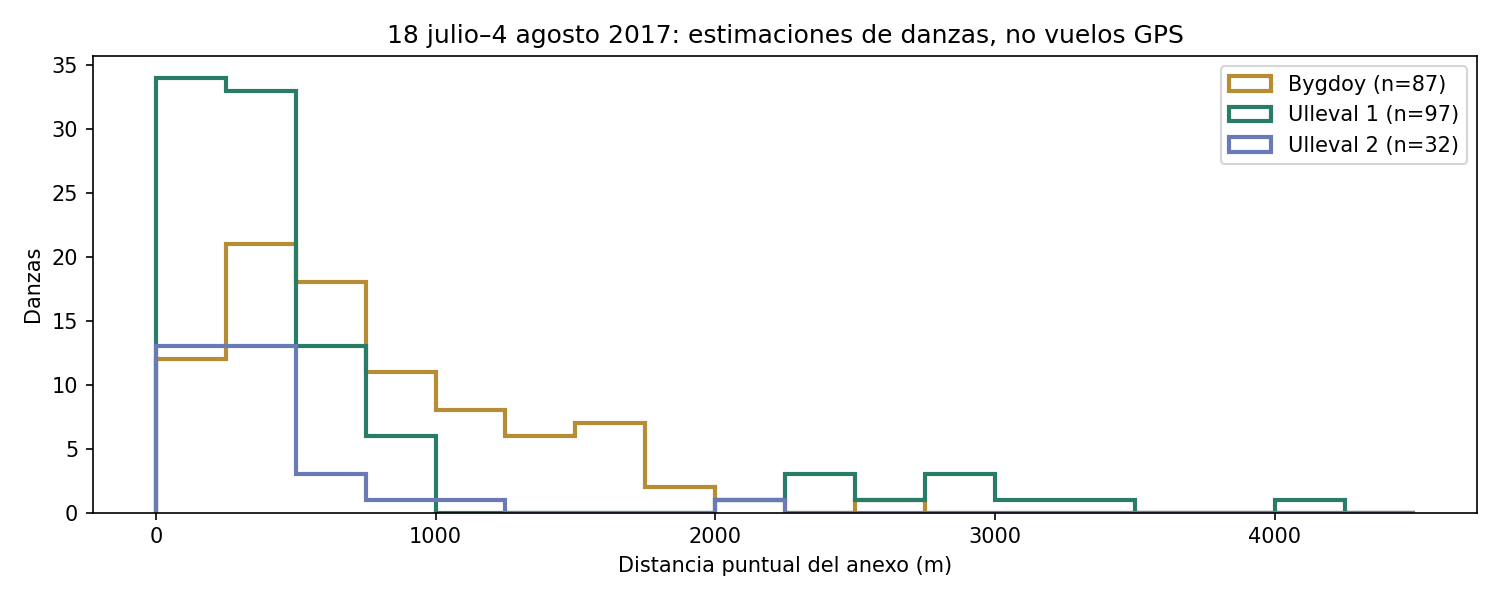

In [6]:
distance_stats=pd.read_csv(OUT/'observed_distances.csv')
display(distance_stats)
display(Image(filename=str(OUT/'observed_distance_distribution.png')))


## 6. Orígenes inferidos y auditoría de CRS

Se invierte la ecuación de vectores descrita en la tesis para revisar consistencia. Los valores siguientes son medianas **inferidas**, no coordenadas topográficas publicadas. Las ubicaciones Ullevål implícitas se separan 3,010 unidades; el texto dice aproximadamente 20 cm. No hay CRS/datum declarado, anexos GIS ni georreferenciación GeoPDF.


In [7]:
display(hives)
print('Separación implícita Ullevål:',decision['implied_ulleval_separation_source_units'])
assert not hives.placement_allowed_for_historical_simulation.any()
assert observations.source_crs.eq('UNCONFIRMED').all()
display(pd.read_csv(OUT/'hive_crs_hypotheses.csv'))


,colony,origin_x_implied_median,origin_y_implied_median,source_crs,coordinate_status,surveyed_location_available,n_vectors,n_origin_consistent_0_1,max_origin_residual_source_units,source_pages,placement_allowed_for_historical_simulation
0,Bygdoy,594293.999999,6.642591e+06,UNCONFIRMED,algebraic_inference_not_verified_historical_location,False,211,209,122.545485,"14-19,50-59",False
1,Ulleval 1,596642.004123,6.646904e+06,UNCONFIRMED,algebraic_inference_not_verified_historical_location,False,190,181,122.548511,"14-19,50-59",False
2,Ulleval 2,596642.004487,6.646901e+06,UNCONFIRMED,algebraic_inference_not_verified_historical_location,False,105,103,39.183151,"14-19,50-59",False


Separación implícita Ullevål: 3.0101465970879158


,colony,assumed_epsg,x_m_conditional,y_m_conditional,longitude_conditional,latitude_conditional,coordinate_status
0,Bygdoy,25832,258839.728861,6.649251e+06,10.686078,59.910020,inferred_unverified_not_for_simulation
1,Ulleval 1,25832,261570.181043,6.653336e+06,10.730055,59.948187,inferred_unverified_not_for_simulation
2,Ulleval 2,25832,261569.908677,6.653333e+06,10.730054,59.948160,inferred_unverified_not_for_simulation
3,Bygdoy,32632,258839.728851,6.649251e+06,10.686078,59.910020,inferred_unverified_not_for_simulation
4,Ulleval 1,32632,261570.181033,6.653336e+06,10.730055,59.948187,inferred_unverified_not_for_simulation
5,Ulleval 2,32632,261569.908667,6.653333e+06,10.730054,59.948160,inferred_unverified_not_for_simulation


## 7. Diagnóstico espacial condicionado, no validación geográfica

UTM32 es una hipótesis coherente con el contexto. EPSG:25832 y 32632 producen casi las mismas ubicaciones al transformar a EPSG:25833, pero su coincidencia **no demuestra cuál se utilizó**. Que NINA 2022 use 25832 tampoco certifica el CRS de la tesis de 2017.

La tabla mide cobertura de centros estimados por los 737 parques originales bajo esas hipótesis. Un destino fuera de parque no significa ausencia de recursos: los jardines privados/agricultura citados por el estudio no son todos parques municipales. La tolerancia de 25 m es un diagnóstico elegido, no un IC de danzas. No se incorporan estos puntos como entradas verificadas al motor.


,colony,assumed_epsg,n,covered_centers,percent_covered_conditional,percent_outside_conditional,percent_within_25m_of_park_conditional,median_distance_to_park_m_conditional,status
0,Bygdoy,25832,87,9,10.344828,89.655172,14.942529,184.335619,CRS_hypothesis_only; decoded_points_not_posterior_footprints
1,Ulleval 1,25832,97,0,0.000000,100.000000,4.123711,268.353458,CRS_hypothesis_only; decoded_points_not_posterior_footprints
2,Ulleval 2,25832,32,1,3.125000,96.875000,12.500000,191.307920,CRS_hypothesis_only; decoded_points_not_posterior_footprints
3,Bygdoy,32632,87,9,10.344828,89.655172,14.942529,184.335631,CRS_hypothesis_only; decoded_points_not_posterior_footprints
4,Ulleval 1,32632,97,0,0.000000,100.000000,4.123711,268.353544,CRS_hypothesis_only; decoded_points_not_posterior_footprints
5,Ulleval 2,32632,32,1,3.125000,96.875000,12.500000,191.307953,CRS_hypothesis_only; decoded_points_not_posterior_footprints


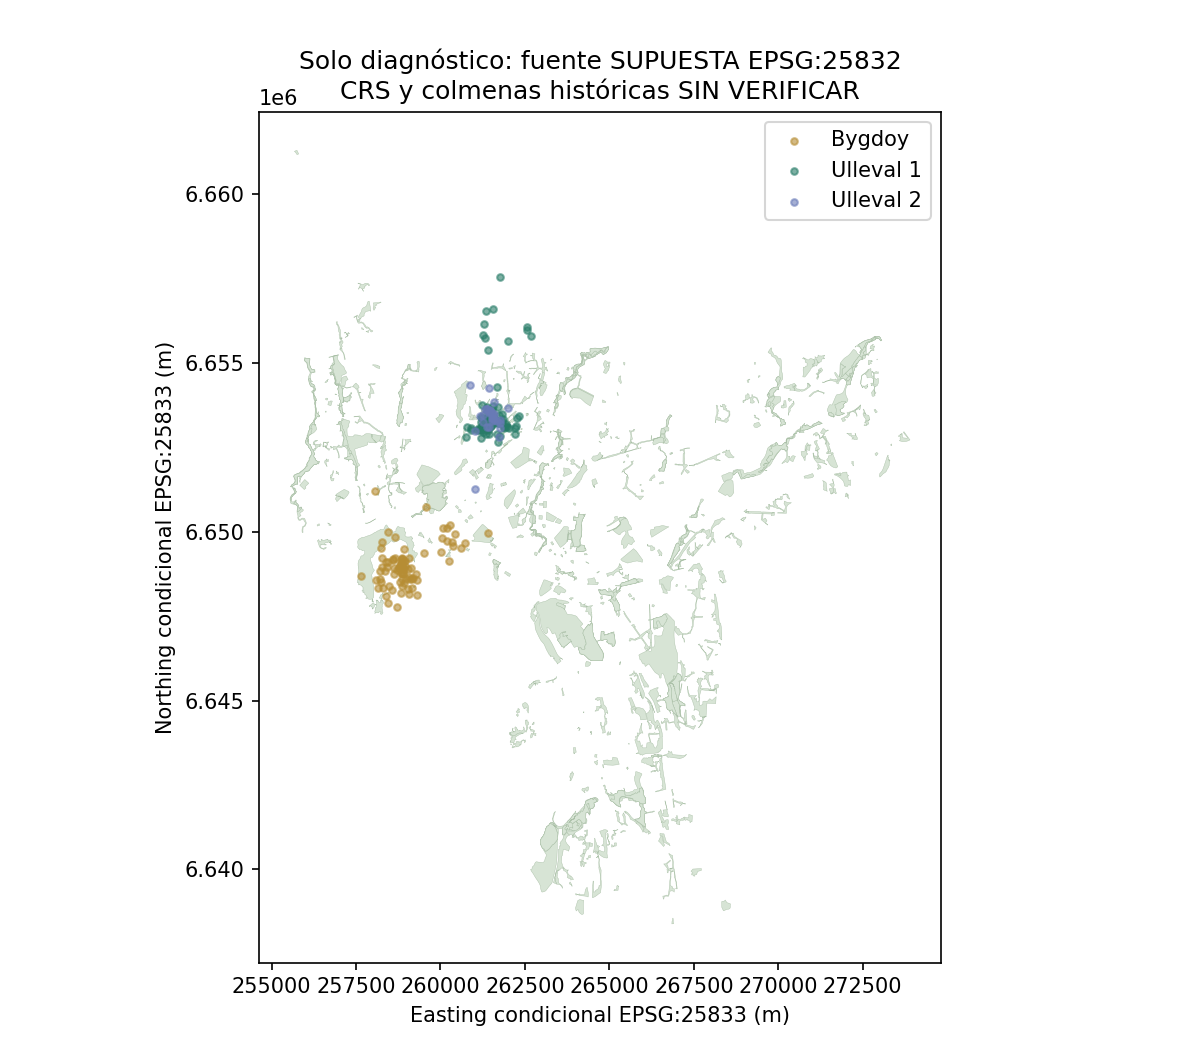

In [8]:
display(pd.read_csv(OUT/'park_coverage_conditional.csv'))
display(Image(filename=str(OUT/'conditional_park_coverage.png')))


## 8. Solapamiento: no confundir indicadores

Jaccard publicado: 0,50 global y 0,39 dentro del percentil 50. Se basa en superficies de probabilidad a 25×25 m. Sin esos rásteres, draws y rejilla, Jaccard de celdas puntuales sería otro indicador; tampoco equivale a `competition_pressure`. No se inventa un solapamiento simulado.


In [9]:
display(pd.read_csv(OUT/'overlap_comparability.csv'))

,analysis,published_value,source_page,reproduced_value,status
0,Jaccard_all_probability_cells,0.50,32,NaN,not_reproducible_without_original_probability_rasters_and_grid
1,Jaccard_within_50th_distance_percentile,0.39,32,NaN,point_cell_overlap_would_be_a_different_statistic


## 9. NINA: acceso numérico adicional y límites

El servicio ArcGIS anterior es TilesOnly. El catálogo oficial localEA, enlazado por SPARE, sí ofrece GeoTIFF/COG con licencia CC-BY 4.0 y contexto 2022. Nativo: EPSG:25832, 1 m. COG reproyectado: EPSG:3857. Usamos **overview publicado factor 8**, píxel 19,109 unidades proyectadas Web Mercator; no es resolución de terreno de 19 m ni resumen zonal exacto de 1 m.

Se obtienen valores para 686 de 737 parques; no se imputan los restantes. La dirección del índice es ambigua en los metadatos y hay valores fuera de la leyenda 0–1; no se recortan ni convierten a RU. La correlación descriptiva con cuota de área sintética no es calibración ni validación temporal de 2017.


,Auditoría NINA
catalog_url,https://s3-ext-1.nina.no/dms/maps/main/localEA/config.json
license,CC-BY 4.0 according to official catalog
catalog_acquisition_period,2022
original_raster,"{'crs': 'EPSG:25832', 'shape': [20614, 19697], 'resolution_projected_units': [1.0, 1.0], 'bounds': [589882..."
analysis_overview,"{'crs': 'EPSG:3857', 'shape': [2208, 2112], 'resolution_projected_units': [19.109257071294063, 19.10925707..."
n_parks_with_numeric_overview_values,686
n_parks_with_values_outside_legend_0_1,349
range_in_park_overview_samples,"[-0.1118325889110565, 1.0984501838684082]"
spearman_rho_raw_index_vs_area_share,-0.094825
full_tiff_downloaded,False


,comparison,n_parks,spearman_rho_descriptive,p_value,status
0,raw_NINA_index_vs_synthetic_area_share,686,-0.094825,NaN,overlapping_parks_not_independent; raw_index_direction_unconfirmed; no_RU_calibration


,patch_id,n_valid_overview_cells,n_pixel_centers_in_polygon,raw_index_mean_approx,raw_index_median_approx,raw_index_min_approx,raw_index_max_approx,overview_factor,status,semantic_direction,exclusive_area_m2,synthetic_initial_resource_share,has_values_outside_legend_0_1
0,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_1,3,3,0.955064,0.957906,0.946157,0.961127,8,approximate_numeric_summary,UNCONFIRMED_metadata_description_and_legend_require_review,384.024302,0.000016,False
1,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_2,8,8,0.665144,0.655029,0.445319,0.953346,8,approximate_numeric_summary,UNCONFIRMED_metadata_description_and_legend_require_review,664.396977,0.000028,False
2,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_3,3,3,0.947368,0.947368,0.947368,0.947368,8,approximate_numeric_summary,UNCONFIRMED_metadata_description_and_legend_require_review,271.897949,0.000012,False
3,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_4,11,11,0.358306,0.344394,0.278016,0.473898,8,approximate_numeric_summary,UNCONFIRMED_metadata_description_and_legend_require_review,953.820872,0.000040,False
4,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_5,8,8,0.780596,0.861986,0.488730,0.952853,8,approximate_numeric_summary,UNCONFIRMED_metadata_description_and_legend_require_review,673.085548,0.000029,False
5,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_6,7,7,0.885927,0.947797,0.590145,0.956753,8,approximate_numeric_summary,UNCONFIRMED_metadata_description_and_legend_require_review,592.402619,0.000025,False
6,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_7,9,9,0.737141,0.781109,0.220096,0.975305,8,approximate_numeric_summary,UNCONFIRMED_metadata_description_and_legend_require_review,759.760536,0.000032,False
7,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_8,7,7,0.650525,0.548394,0.472405,0.914119,8,approximate_numeric_summary,UNCONFIRMED_metadata_description_and_legend_require_review,595.219763,0.000025,False
8,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_9,7,7,0.421509,0.411654,0.397384,0.449567,8,approximate_numeric_summary,UNCONFIRMED_metadata_description_and_legend_require_review,795.123391,0.000034,False
9,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_10,3,3,0.952199,0.989822,0.856775,1.009999,8,approximate_numeric_summary,UNCONFIRMED_metadata_description_and_legend_require_review,438.108133,0.000019,True


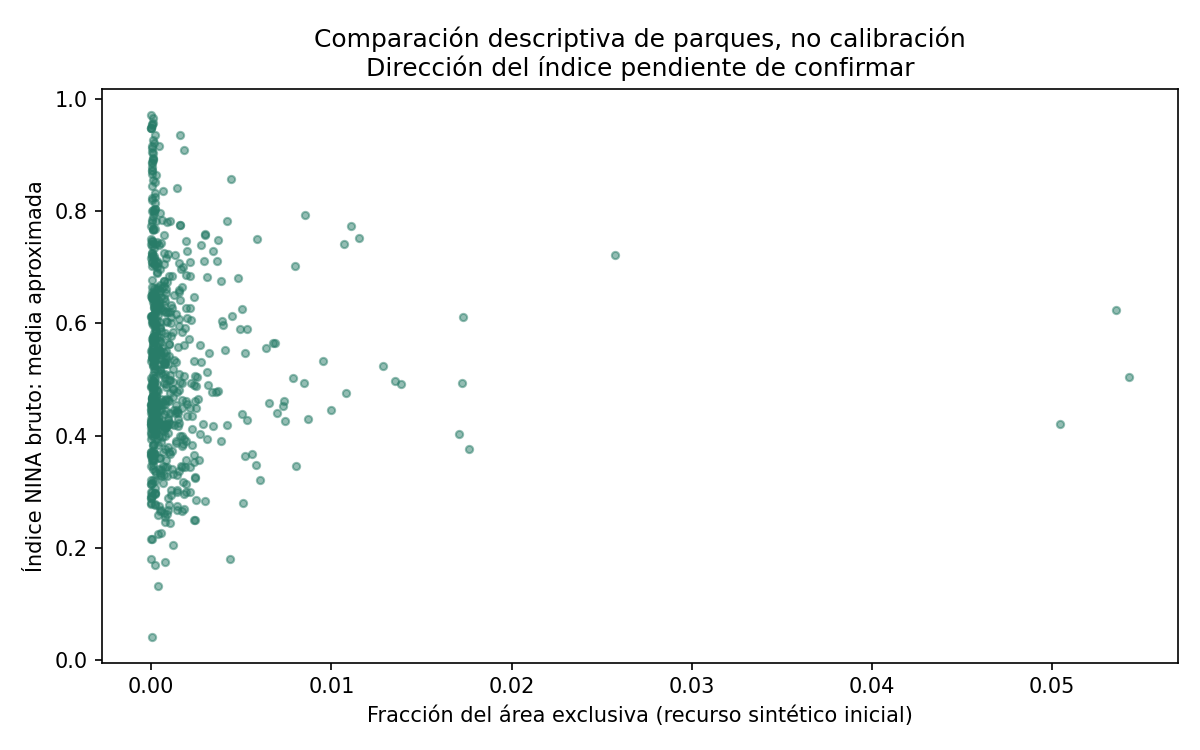

In [10]:
nina=json.loads((OUT/'nina_numeric_audit.json').read_text(encoding='utf-8'))
display(pd.Series({k:nina[k] for k in ['catalog_url','license','catalog_acquisition_period','original_raster','analysis_overview','n_parks_with_numeric_overview_values','n_parks_with_values_outside_legend_0_1','range_in_park_overview_samples','spearman_rho_raw_index_vs_area_share','full_tiff_downloaded']}).to_frame('Auditoría NINA'))
display(pd.read_csv(OUT/'nina_resource_relation.csv'))
display(pd.read_csv(OUT/'nina_park_index_approximate.csv').head(12))
display(Image(filename=str(OUT/'nina_resource_relation.png')))


## 10. Reutilización de Dryad

Se consulta `docs/project2/REAL_WORLD_VALIDATION.md` y la evidencia existente sin regenerarla. Los MAE/RMSE de densidad y actividad son de **referentes estadísticos con separación por sitio**, no errores del motor de colmenas. La temperatura es un registro/estrato del referente, no una respuesta causal calibrada de nuestras abejas.


In [11]:
display(pd.read_csv(ROOT/'results/project2/scientific_validation/empirical_errors.csv'))

,dataset,method,metric,estimate,ci95_low,ci95_high,unit,train_sites,test_sites,train_units,test_units,train_bootstrap_replicates
0,flowers,global,MAE,10.227028,7.676632,12.969134,flores/m²,79,20,79,20,30
1,flowers,global,RMSE,11.788499,8.933878,14.797095,flores/m²,79,20,79,20,30
2,flowers,stratified,MAE,11.106329,8.462745,13.920433,flores/m²,79,20,79,20,30
3,flowers,stratified,RMSE,12.700899,9.893508,15.306625,flores/m²,79,20,79,20,30
4,activity,global,MAE,0.925099,0.697287,1.178132,conteos registrados/minuto de sesión candidata,79,20,169,47,30
5,activity,global,RMSE,1.126583,0.842474,1.432922,conteos registrados/minuto de sesión candidata,79,20,169,47,30
6,activity,stratified,MAE,0.842494,0.626203,1.068460,conteos registrados/minuto de sesión candidata,79,20,169,47,30
7,activity,stratified,RMSE,1.055442,0.808794,1.300252,conteos registrados/minuto de sesión candidata,79,20,169,47,30


## 11. Hallazgos, recomendaciones y productos no generados

No se altera el modelo para lograr semejanza. Se mantienen balance, reglas, recursos sintéticos y restricciones K=5 del experimento principal. Una validación histórica futura requerirá interfaz separada para ubicaciones verificadas, K=3 y un banco nuevo de al menos 30 seeds/configuración. No se duplican esos experimentos antes de superar el punto de control.


In [12]:
display(pd.read_csv(OUT/'findings_recommendations.csv'))
display(pd.read_csv(OUT/'requested_outputs_status.csv'))


,Hallazgo,Evidencia cuantitativa,Posible causa,Implicación para el modelo,Cambio recomendado,Prioridad
0,Georreferenciación pendiente,0 CRS declarados y 0 archivos GIS adjuntos en PDF,Falta proyecto R/QGIS o metadatos,No inicializar colmenas verificadas,Solicitar CRS/datum y coordenadas originales,Esencial
1,Dos colmenas cercanas: discrepancia,"Orígenes implícitos separados 3,010 unidades vs ~0,2 m en texto",Redondeo o procesamiento por aclarar,No fijar ni colapsar dos sitios inventados,Confirmar ambos orígenes con fuente primaria,Esencial
2,Calidad de registros,"506 filas; 1 distancia negativa, 2 relojes inválidos, 5 discrepancias de IDs",Transcripción/procesamiento de fuente por revisar,Filtros separados y trazabilidad por fila,No reparar automáticamente; pedir aclaración,Alta
3,Cobertura temporal parcial,"216/506 filas dentro de 18 días, 9/10/8 fechas por colonia",Filmación selectiva con buen clima,No comparar todos los días/horas como observados,"Alinear fechas, esfuerzo y selección de danzas",Alta
4,Cola de distancias supera radio,"Ullevål 1: 3/97 distancias puntuales >3 km; máximo 4205,4 m",Radio fijo podría truncar destinos,No asumir que 3 km cubre toda la muestra,"Estudiar radio tras confirmar ubicaciones, sin ajustar para parecerse",Alta
5,Posible falta de recursos fuera de parques,"Bajo UTM32 supuesto: 89,66%/100%/96,88% fuera del catálogo","Jardines privados, campos u omisión cartográfica; no verificado individualmente",Cobertura condicional no equivale a ausencia de flores,Confirmar CRS y auditar catálogo de recursos urbanos,Alta
6,Solapamiento no comparable,"Jaccard publicado 0,50/0,39; sin superficies originales",Puntos del anexo no son nubes de probabilidad,No comparar con competition_pressure ni ocupación puntual,Obtener rásteres de probabilidad y rejilla,Alta
7,Proceso de observación no modelado,1–2 h/colmena/día con buen clima; danzas tras forrajeo rentable,Sesgo de selección de retornos y recurso,Todos los viajes del motor no son todas las danzas,Diseñar operador de observación separado,Alta
8,Competencia externa ausente,3 colonias de ~60000 abejas adicionales citadas en Sogn; observadas ~5000/colonia,Entorno no representado por solo nuestras colonias,Presión interna no mide competencia ecológica total,Investigar presión externa/reclutamiento con evidencia adicional,Media
9,Fuente NINA numérica adicional,"GeoTIFF nativo 1 m, EPSG:25832, licencia CC-BY 4.0, contexto 2022",Catálogo distinto del servicio TilesOnly,No reemplazar ni convertir índice a RU,Resolver semántica/rango y evaluar resumen nativo,Media


,requested_output,status,evidence_or_reason
0,Observaciones por colonia,completo,observations_by_colony.csv
1,Incluidos/excluidos,completo_con_filtros_separados,inclusion_exclusion.csv
2,Cobertura de parques,solo_condicional_CRS_no_verificado,park_coverage_conditional.csv
3,Distancias observadas y simuladas,solo_observadas; simulación_no_habilitada,observed_distances.csv
4,Errores absolutos/relativos del simulador,no_calculados_por_falta_de_correspondencia_verificada,No sustituir con diferencias entre estimandos del PDF
5,Resultados por semilla histórica,no_generados; 0 simulaciones,El checkpoint detuvo la fase experimental
6,Solapamiento comparable,no_reproducible_con_datos_disponibles,overlap_comparability.csv
7,Limitaciones/mejoras,completo,findings_recommendations.csv


## 12. Dictamen final de viabilidad

**Detener la implementación del escenario histórico.** La recuperación de tablas es válida; la georreferenciación de colmenas todavía no está verificada. La decisión conservadora evita presentar hipótesis como una reconstrucción confirmada. No implica que los datos sean inútiles o que nunca pueda hacerse la comparación.


In [13]:
display(pd.Series(decision).to_frame('Dictamen'))
try:
    require_historical_feasibility(decision)
except HistoricalFeasibilityError as exc:
    print('PUNTO DE CONTROL:',exc)
assert decision['simulation_runs_executed']==0
assert not decision['new_simulation_seed_bank_created']


,Dictamen
ready_for_historical_simulation,False
verified_historical_hive_positions,False
source_crs_verified,False
appendix_individual_rows_recovered,506
project_window_rows,216
implied_ulleval_separation_source_units,3.010147
published_ulleval_separation_approx_m,0.2
posterior_probability_rasters_available,False
decision,STOP_AFTER_FEASIBILITY_AUDIT
reasons,"[No declared source CRS/datum or georeferencing in the supplied PDF, Hive coordinates are algebraically in..."


PUNTO DE CONTROL: Auditoría no habilita simulación histórica: faltan CRS y ubicaciones verificadas. No sustituirlos por hipótesis.


## Próximos pasos y alcance de optimización

Obtener CRS/datum, coordenadas originales o proyecto R/QGIS, aclarar filas anómalas y distancia entre colmenas; pedir rásteres/draws para solapamiento y revisar reutilización. Recién entonces definir operador de observación: retornos con recursos son una submuestra candidata, pero no todas las abejas que regresan danzan. La filmación y condiciones meteorológicas son selectivas.

No se ha validado el recurso sintético, el impacto en abejas silvestres ni NSGA-II en realidad. Las conclusiones originales permanecen dentro del escenario simulado; no se necesita repetir ahora la búsqueda. Cambios futuros de recursos, paisaje o reglas deberán tener otra identidad y evaluar conjuntamente todos los métodos.
